In [ ]:

import os

print(os.listdir('/content'))


['.config', 'roads.csv', 'traffic.csv', 'accidents.csv', 'vehicles.csv', 'weather.csv', 'sample_data']


In [ ]:

import pandas as pd

# Load the five datasets
accidents = pd.read_csv('/content/accidents.csv')
roads = pd.read_csv('/content/roads.csv')
weather = pd.read_csv('/content/weather.csv')
traffic = pd.read_csv('/content/traffic.csv')
vehicles = pd.read_csv('/content/vehicles.csv')

# Inspect each dataset
datasets = {
    "Accidents": accidents,
    "Roads": roads,
    "Weather": weather,
    "Traffic": traffic,
    "Vehicles": vehicles
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name.upper()} DATASET")
    print(f"Records: {df.shape[0]}")
    print(f"Attributes: {df.shape[1]}")
    print("Columns:", list(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.head(3))



ACCIDENTS DATASET
Records: 1000
Attributes: 5
Columns: ['incident_id', 'date', 'time', 'location', 'severity']
Missing values: 3
Duplicate rows: 0


,incident_id,date,time,location,severity
0,INC00001,2025-11-11,02:15,School Zone,Fatal
1,INC00002,2025-05-21,01:15,Highway East,Minor
2,INC00003,2025-05-30,22:15,School Zone,Minor



ROADS DATASET
Records: 1000
Attributes: 4
Columns: ['incident_id', 'road_type', 'junction', 'speed_limit']
Missing values: 0
Duplicate rows: 0


,incident_id,road_type,junction,speed_limit
0,INC00001,Highway,No Junction,30
1,INC00002,Industrial Road,Roundabout,60
2,INC00003,Residential Road,Roundabout,60



WEATHER DATASET
Records: 1000
Attributes: 4
Columns: ['incident_id', 'rain', 'visibility', 'condition']
Missing values: 3
Duplicate rows: 0


,incident_id,rain,visibility,condition
0,INC00001,Yes,Moderate,Clear
1,INC00002,No,Moderate,Clear
2,INC00003,No,Moderate,Clear



TRAFFIC DATASET
Records: 1000
Attributes: 3
Columns: ['incident_id', 'traffic_volume', 'peak_flag']
Missing values: 0
Duplicate rows: 0


,incident_id,traffic_volume,peak_flag
0,INC00001,952,No
1,INC00002,833,No
2,INC00003,1415,No



VEHICLES DATASET
Records: 1000
Attributes: 3
Columns: ['incident_id', 'vehicle_category', 'vehicle_count']
Missing values: 0
Duplicate rows: 0


,incident_id,vehicle_category,vehicle_count
0,INC00001,Truck,3
1,INC00002,Bicycle,3
2,INC00003,Bicycle,2


In [ ]:

# 1. Check duplicate incident IDs
print("Duplicate incident IDs in accidents:",
      accidents["incident_id"].duplicated().sum())

# 2. Check missing locations
print("\nMissing locations:")
print(accidents[accidents["location"].isna()])

# 3. Check severity values
print("\nSeverity categories:")
print(accidents["severity"].value_counts(dropna=False))

# 4. Check road type labels
print("\nRoad type categories:")
print(roads["road_type"].value_counts(dropna=False))

# 5. Check missing weather observations
print("\nMissing weather values:")
print(weather.isnull().sum())

# 6. Check whether incident IDs match across files
for name, df in datasets.items():
    print(name, "unique incident IDs:",
          df["incident_id"].nunique())


Duplicate incident IDs in accidents: 1

Missing locations:
    incident_id        date   time location  severity
12     INC00013  2025-12-18  00:15      NaN  Moderate
87     INC00088  2024-03-05  05:45      NaN  Moderate
202    INC00203  2025-05-04  06:45      NaN  Moderate

Severity categories:
severity
Minor       413
Moderate    352
Serious     176
Fatal        58
Unknown       1
Name: count, dtype: int64

Road type categories:
road_type
School Zone         209
Urban Road          207
Highway             201
Industrial Road     196
Residential Road    185
urban road            1
Residential           1
Name: count, dtype: int64

Missing weather values:
incident_id    0
rain           0
visibility     0
condition      3
dtype: int64
Accidents unique incident IDs: 999
Roads unique incident IDs: 1000
Weather unique incident IDs: 1000
Traffic unique incident IDs: 1000
Vehicles unique incident IDs: 1000


In [ ]:

import pandas as pd
import numpy as np

# Work on copies so the original data remains available
acc = accidents.copy()
rd = roads.copy()
we = weather.copy()
tr = traffic.copy()
vh = vehicles.copy()

# 1. Remove duplicate accident IDs (keep the first occurrence)
acc = acc.drop_duplicates(subset="incident_id", keep="first")

# 2. Handle missing locations
acc["location"] = acc["location"].fillna("Unknown")

# 3. Mark invalid severity as missing
acc["severity"] = acc["severity"].replace("Unknown", np.nan)

# 4. Standardize road type labels
rd["road_type"] = rd["road_type"].str.strip().str.lower()

rd["road_type"] = rd["road_type"].replace({
    "urban road": "Urban Road",
    "residential": "Residential Road",
    "residential road": "Residential Road",
    "highway": "Highway",
    "industrial road": "Industrial Road",
    "school zone": "School Zone"
})

# 5. Handle missing weather conditions with the most common value
we["condition"] = we["condition"].fillna(we["condition"].mode()[0])

# 6. Merge the five datasets using incident_id
df = acc.merge(rd, on="incident_id", how="inner")
df = df.merge(we, on="incident_id", how="inner")
df = df.merge(tr, on="incident_id", how="inner")
df = df.merge(vh, on="incident_id", how="inner")

# 7. Inspect the cleaned dataset
print("Cleaned dataset shape:", df.shape)
print("Unique incident IDs:", df["incident_id"].nunique())
print("\nMissing values:")
print(df.isnull().sum())
print("\nRemaining duplicate incident IDs:",
      df["incident_id"].duplicated().sum())

display(df.head())


Cleaned dataset shape: (999, 15)
Unique incident IDs: 999

Missing values:
incident_id         0
date                0
time                0
location            0
severity            1
road_type           0
junction            0
speed_limit         0
rain                0
visibility          0
condition           0
traffic_volume      0
peak_flag           0
vehicle_category    0
vehicle_count       0
dtype: int64

Remaining duplicate incident IDs: 0


,incident_id,date,time,location,severity,road_type,junction,speed_limit,rain,visibility,condition,traffic_volume,peak_flag,vehicle_category,vehicle_count
0,INC00001,2025-11-11,02:15,School Zone,Fatal,Highway,No Junction,30,Yes,Moderate,Clear,952,No,Truck,3
1,INC00002,2025-05-21,01:15,Highway East,Minor,Industrial Road,Roundabout,60,No,Moderate,Clear,833,No,Bicycle,3
2,INC00003,2025-05-30,22:15,School Zone,Minor,Residential Road,Roundabout,60,No,Moderate,Clear,1415,No,Bicycle,2
3,INC00004,2025-08-19,13:45,Bus Stand Road,Moderate,Highway,Roundabout,40,No,Poor,Clear,705,No,Car,1
4,INC00005,2024-06-25,11:15,School Zone,Moderate,Urban Road,Roundabout,60,No,Poor,Clear,928,No,Truck,2


In [ ]:
import matplotlib.pyplot as plt

Top 5 accident locations


,count
location,
Central Junction,200
Market Road,151
Highway East,143
Industrial Area,125
Bus Stand Road,113


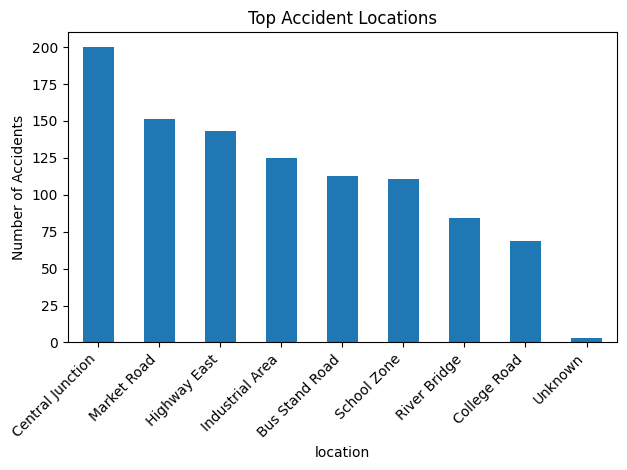

Accidents by time of day


,count
time_of_day,
Morning,312
Night,309
Afternoon,209
Evening,169


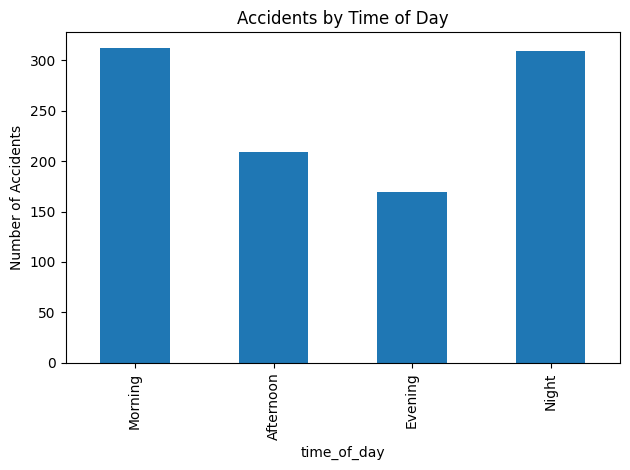

Accidents by severity


,count
severity,
Minor,412
Moderate,352
Serious,176
Fatal,58


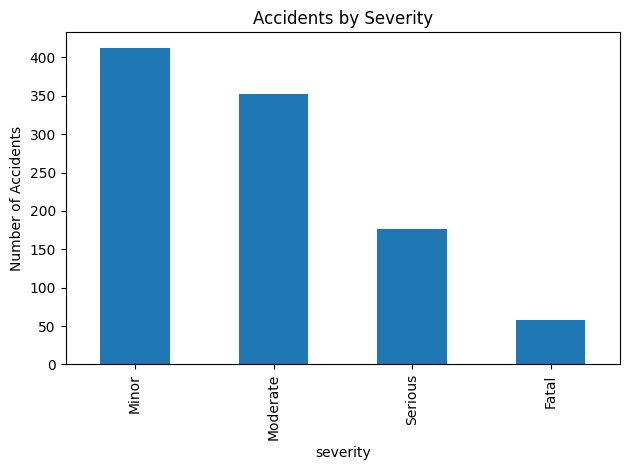

Accidents by weather condition


,count
condition,
Clear,497
Rainy,221
Cloudy,191
Foggy,90


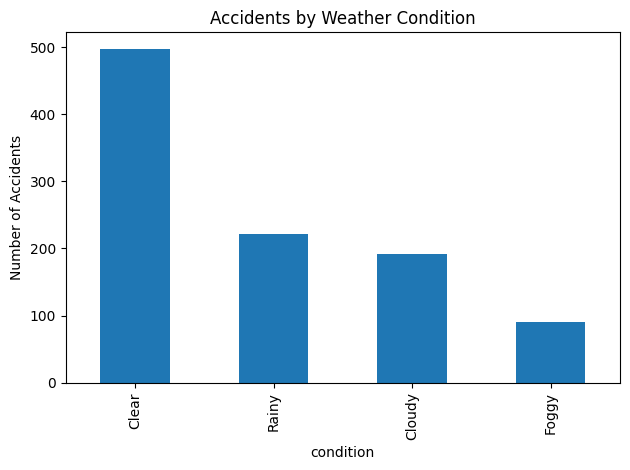

Accidents by road type


,count
road_type,
School Zone,209
Urban Road,208
Highway,200
Industrial Road,196
Residential Road,186


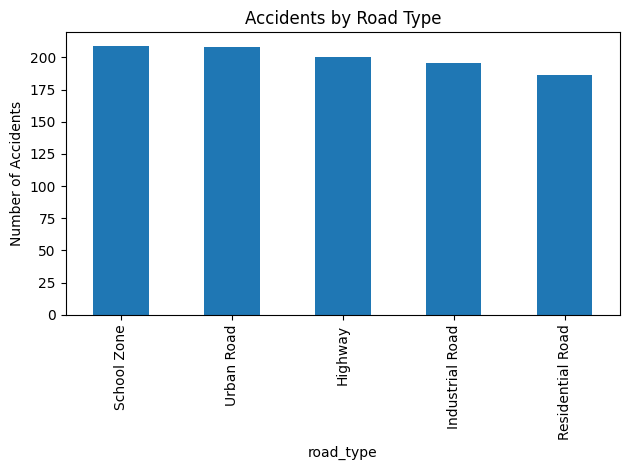

In [ ]:

# Prepare time features
df["hour"] = pd.to_datetime(
    df["time"], format="%H:%M", errors="coerce"
).dt.hour

def get_period(hour):
    if pd.isna(hour):
        return "Unknown"
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    return "Night"

df["time_of_day"] = df["hour"].apply(get_period)

# 1. Accident hotspots
print("Top 5 accident locations")
display(df["location"].value_counts().head(5))

df["location"].value_counts().head(10).plot(
    kind="bar", title="Top Accident Locations",
    ylabel="Number of Accidents"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 2. Accidents by time of day
print("Accidents by time of day")
display(df["time_of_day"].value_counts())

df["time_of_day"].value_counts().reindex(
    ["Morning", "Afternoon", "Evening", "Night"],
    fill_value=0
).plot(kind="bar", title="Accidents by Time of Day",
       ylabel="Number of Accidents")
plt.tight_layout()
plt.show()

# 3. Accident severity
print("Accidents by severity")
display(df["severity"].value_counts())

df["severity"].value_counts().plot(
    kind="bar", title="Accidents by Severity",
    ylabel="Number of Accidents"
)
plt.tight_layout()
plt.show()

# 4. Accidents by weather condition
print("Accidents by weather condition")
display(df["condition"].value_counts())

df["condition"].value_counts().plot(
    kind="bar", title="Accidents by Weather Condition",
    ylabel="Number of Accidents"
)
plt.tight_layout()
plt.show()

# 5. Accidents by road type
print("Accidents by road type")
display(df["road_type"].value_counts())

df["road_type"].value_counts().plot(
    kind="bar", title="Accidents by Road Type",
    ylabel="Number of Accidents"
)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Feature engineering
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month

# Keep rows with a known target
model_df = df.dropna(subset=["severity"]).copy()

# Input features and target
features = [
    "location", "road_type", "junction", "speed_limit",
    "rain", "visibility", "condition", "traffic_volume",
    "peak_flag", "vehicle_category", "vehicle_count",
    "hour", "day_of_week", "month"
]

X = model_df[features]
y = model_df["severity"]

# Identify categorical and numerical features
categorical = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Encode categorical features
preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numerical", "passthrough", numerical)
])

# Build and train model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

# Evaluate actual performance
accuracy = accuracy_score(y_test, predictions)
f1 = f1_score(y_test, predictions, average="macro")

print("Algorithm: Random Forest Classifier")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Macro F1-score: {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, predictions))


Algorithm: Random Forest Classifier
Training records: 798
Testing records: 200
Accuracy: 0.3900 (39.00%)
Macro F1-score: 0.2124

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.00      0.00      0.00        12
       Minor       0.42      0.66      0.51        83
    Moderate       0.34      0.33      0.34        70
     Serious       0.00      0.00      0.00        35

    accuracy                           0.39       200
   macro avg       0.19      0.25      0.21       200
weighted avg       0.29      0.39      0.33       200



In [ ]:

# Export cleaned dataset and analysis summaries

# 1. Save cleaned dataset
df.to_csv("CH15_Cleaned_Accidents.csv", index=False)

# 2. Create summary tables
location_summary = df["location"].value_counts().reset_index()
location_summary.columns = ["Location", "Accident_Count"]

time_summary = df["time_of_day"].value_counts().reset_index()
time_summary.columns = ["Time_of_Day", "Accident_Count"]

severity_summary = df["severity"].value_counts(dropna=False).reset_index()
severity_summary.columns = ["Severity", "Accident_Count"]

weather_summary = df["condition"].value_counts().reset_index()
weather_summary.columns = ["Weather_Condition", "Accident_Count"]

road_summary = df["road_type"].value_counts().reset_index()
road_summary.columns = ["Road_Type", "Accident_Count"]

# 3. Create Excel workbook with separate sheets
with pd.ExcelWriter("CH15_Road_Safety_Analysis.xlsx") as writer:
    df.to_excel(writer, sheet_name="Cleaned_Data", index=False)
    location_summary.to_excel(writer, sheet_name="Locations", index=False)
    time_summary.to_excel(writer, sheet_name="Time_Analysis", index=False)
    severity_summary.to_excel(writer, sheet_name="Severity", index=False)
    weather_summary.to_excel(writer, sheet_name="Weather", index=False)
    road_summary.to_excel(writer, sheet_name="Road_Types", index=False)

print("Files created successfully!")


Files created successfully!
